# 16. End-to-End Streaming Walkthrough

Most machine learning assumes a static dataset — you load it once, split it, and train. Streaming
flips that assumption: data arrives continuously, the underlying distribution may shift over time,
and you cannot store or revisit the entire history.

TuiML supports streaming through `partial_fit` — a method available on several classifiers that
updates a model on a chunk of data without discarding what it already learned. This chapter shows
how to use it, how to evaluate it fairly, and how to detect and respond to concept drift.

**You will learn:**

- how to generate a synthetic data stream with `Agrawal` and `Hyperplane`
- how to train a model incrementally using `partial_fit`
- how prequential (test-then-train) evaluation works
- how to detect concept drift by watching accuracy degrade
- which TuiML classifiers support streaming and what their trade-offs are

**Prerequisites:** chapters 0, 1, and 2.

## 16.1 Generating a data stream

The `Agrawal` generator produces a binary classification stream based on a set of loan-approval
rules. It has nine features (`salary`, `commission`, `age`, etc.) and two classes. We generate
3 000 samples and treat them as arriving 200 at a time.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from tuiml.datasets.generators import Agrawal

N_SAMPLES = 3000
CHUNK_SIZE = 200

stream_data = Agrawal(n_samples=N_SAMPLES, function=1, random_state=42).generate()
X_stream, y_stream = stream_data.X, stream_data.y

n_chunks = N_SAMPLES // CHUNK_SIZE

print(f"Stream: {N_SAMPLES} samples, {X_stream.shape[1]} features, {len(np.unique(y_stream))} classes")
print(f"Features: {stream_data.feature_names}")
print(f"{n_chunks} chunks of {CHUNK_SIZE} samples")

Stream: 3000 samples, 9 features, 2 classes
Features: ['salary', 'commission', 'age', 'education_level', 'car', 'zipcode', 'house_value', 'years_house', 'loan']
15 chunks of 200 samples


## 16.2 Prequential (test-then-train) evaluation

Standard train/test split does not make sense for streams — the model has not seen any data yet
when the first test sample arrives. **Prequential evaluation** solves this:

1. For each chunk, **first test** the current model on that chunk.
2. Then **train** the model on the same chunk using `partial_fit`.

This gives an accuracy estimate for every moment in time, not just at the end, and it is always
honest: the model never predicts data it has already been trained on.

### Understanding First-Chunk Handling

Because the model starts with zero prior knowledge, Chunk 1 requires special handling:
- **The first chunk initializes and trains the model**: we call `partial_fit` on Chunk 1 so the classifier learns initial class priors and feature distributions.
- **There is no previous prediction for the initial chunk**: because no trained model existed prior to Chunk 1, the model cannot make a genuine prequential prediction on it.
- **Actual prequential evaluation starts from subsequent chunks (Chunk 2 onwards)**: starting with Chunk 2, the model predicts the new chunk before training on it.
- **Placeholder values are not real accuracy**: any placeholder value recorded or printed for Chunk 1 (such as `0.5`) serves solely as an illustrative display marker and should **not** be interpreted as a real model accuracy score.


In [2]:
from tuiml.algorithms.bayesian import NaiveBayesClassifier
from tuiml.evaluation import accuracy_score

nb = NaiveBayesClassifier()
prequential_accs = []

for i in range(n_chunks):
    start = i * CHUNK_SIZE
    end = start + CHUNK_SIZE
    Xi = X_stream[start:end]
    yi = y_stream[start:end]

    # Test first -- the model has not seen this chunk yet
    if i == 0:
        # First chunk initializes the model: no prior model exists to make real predictions.
        # Record a 0.5 placeholder for display; genuine prequential tracking starts at Chunk 2.
        acc = 0.5
        # Still train before the next chunk
        nb.partial_fit(Xi, yi)
        print(f"Chunk  1 (test-then-train): acc=0.500  [initialization chunk -- actual evaluation begins at chunk 2]")
    else:
        acc = accuracy_score(yi, nb.predict(Xi))
        # Then train
        nb.partial_fit(Xi, yi)
        prequential_accs.append(acc)
        if i < 5 or i == n_chunks - 1:
            print(f"Chunk {i+1:2d}: acc={acc:.3f}")

print(f"\nMean prequential accuracy (chunks 2-15): {np.mean(prequential_accs):.3f}")


Chunk  1 (test-then-train): acc=0.500  [initialization chunk -- actual evaluation begins at chunk 2]
Chunk  2: acc=0.790
Chunk  3: acc=0.860
Chunk  4: acc=0.790
Chunk  5: acc=0.790


Chunk 15: acc=0.815

Mean prequential accuracy (chunks 2-15): 0.816


## 16.3 Visualising accuracy over time

Plotting the per-chunk accuracy reveals whether the model improves as it sees more data, or
whether there is degradation that might signal a distribution shift.


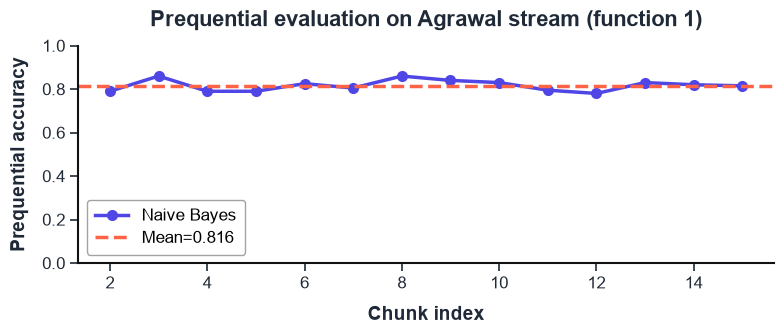

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.5))
chunks = list(range(2, n_chunks + 1))
ax.plot(chunks, prequential_accs, marker="o", color="#4f46e5", label="Naive Bayes")
ax.axhline(np.mean(prequential_accs), color="tomato", linestyle="--", label=f"Mean={np.mean(prequential_accs):.3f}")
ax.set_xlabel("Chunk index")
ax.set_ylabel("Prequential accuracy")
ax.set_title("Prequential evaluation on Agrawal stream (function 1)")
ax.set_ylim(0, 1)
ax.legend()
plt.tight_layout()
plt.show()

## 16.4 Simulating concept drift

Concept drift occurs when the underlying relationship between features and labels changes over
time — a fraud pattern evolves, a sensor recalibrates, a market shifts. We simulate abrupt
drift by switching from Agrawal function 1 to function 7 halfway through the stream.

A model trained on one concept will show a sudden accuracy drop when the concept changes.


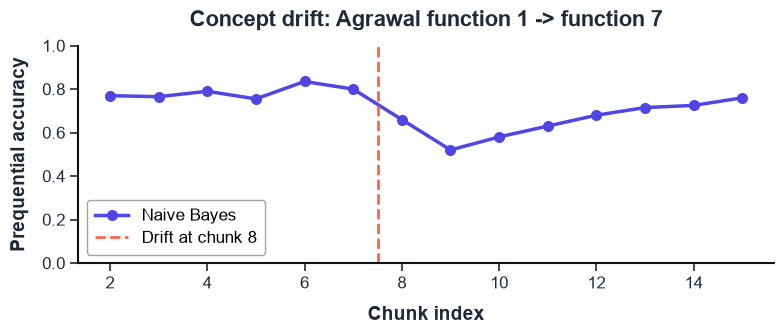

In [4]:
# Build a drifting stream: first half is function 1, second half is function 7
half = N_SAMPLES // 2
d1 = Agrawal(n_samples=half, function=1, random_state=0).generate()
d2 = Agrawal(n_samples=half, function=7, random_state=0).generate()

X_drift = np.vstack([d1.X, d2.X])
y_drift = np.hstack([d1.y, d2.y])

n_chunks_drift = N_SAMPLES // CHUNK_SIZE
drift_point_chunk = half // CHUNK_SIZE  # chunk index where drift begins

nb_drift = NaiveBayesClassifier()
drift_accs = []

for i in range(n_chunks_drift):
    start = i * CHUNK_SIZE
    end = start + CHUNK_SIZE
    Xi = X_drift[start:end]
    yi = y_drift[start:end]

    if i == 0:
        nb_drift.partial_fit(Xi, yi)
        drift_accs.append(np.nan)
    else:
        acc = accuracy_score(yi, nb_drift.predict(Xi))
        drift_accs.append(acc)
        nb_drift.partial_fit(Xi, yi)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(range(1, n_chunks_drift + 1), drift_accs, marker="o", color="#4f46e5", label="Naive Bayes")
ax.axvline(drift_point_chunk + 0.5, color="tomato", linestyle="--", linewidth=2,
           label=f"Drift at chunk {drift_point_chunk + 1}")
ax.set_xlabel("Chunk index")
ax.set_ylabel("Prequential accuracy")
ax.set_title("Concept drift: Agrawal function 1 -> function 7")
ax.set_ylim(0, 1)
ax.legend()
plt.tight_layout()
plt.show()

## 16.5 Responding to drift: restarting the model

When concept drift occurs, a model trained on earlier distributions may suffer permanent accuracy
degradation unless it adapts. The simplest recovery strategy for abrupt drift is to discard the
obsolete model state and reinitialize learning from scratch on fresh data.

### Teaching Heuristic vs. Formal Drift Detectors

The implementation below demonstrates this recovery pattern using a **simple accuracy-based drift heuristic**:
- We track accuracy over a sliding window (`WINDOW = 3` chunks) and trigger a model reset when the rolling average drops below an empirical threshold (`DRIFT_THRESHOLD = 0.65`).
- **Teaching and demonstration purpose only**: this threshold/window approach is designed purely as an intuitive pedagogical example to show how resetting clears stale parameters and allows recovery.
- **Not a formal drift detector**: real-world streaming systems do not rely on ad-hoc accuracy thresholds. Formal drift-detection algorithms such as **ADWIN (Adaptive Windowing)**, **DDM (Drift Detection Method)**, or **EDDM** statistically monitor distribution changes, bound false positive rates, and automatically adapt window sizes without manual threshold tuning. (In production TuiML environments, formal detectors can be integrated via the optional `tuiml[capymoa]` extension).


In [5]:
DRIFT_THRESHOLD = 0.65  # teaching threshold: trigger if accuracy drops below this
WINDOW = 3              # sliding window size to check for sustained drop

nb_reset = NaiveBayesClassifier()
reset_accs = []
recent_accs = []

for i in range(n_chunks_drift):
    start = i * CHUNK_SIZE
    end = start + CHUNK_SIZE
    Xi = X_drift[start:end]
    yi = y_drift[start:end]

    if i == 0:
        nb_reset.partial_fit(Xi, yi)
        reset_accs.append(np.nan)
        continue

    acc = accuracy_score(yi, nb_reset.predict(Xi))
    recent_accs.append(acc)

    # Simple accuracy-based drift heuristic (teaching demo, not a formal detector like ADWIN):
    # if recent window accuracy drops below threshold, reset the model
    if len(recent_accs) >= WINDOW and np.mean(recent_accs[-WINDOW:]) < DRIFT_THRESHOLD:
        print(f"Drift detected at chunk {i+1} (accuracy {acc:.3f} < threshold {DRIFT_THRESHOLD})")
        print(f"  -> resetting model")
        nb_reset = NaiveBayesClassifier()   # fresh model
        recent_accs.clear()

    nb_reset.partial_fit(Xi, yi)
    reset_accs.append(acc)

valid = [a for a in drift_accs if not np.isnan(a)]
valid_reset = [a for a in reset_accs if not np.isnan(a)]
print(f"\nNo-reset mean accuracy  : {np.mean(valid):.3f}")
print(f"With-reset mean accuracy: {np.mean(valid_reset):.3f}")


Drift detected at chunk 10 (accuracy 0.580 < threshold 0.65)
  -> resetting model

No-reset mean accuracy  : 0.713
With-reset mean accuracy: 0.764


## 16.6 Comparing streaming classifiers on a continuous stream

TuiML's `partial_fit` classifiers make different trade-offs. Linear streaming models like `SGDClassifier` and `PerceptronClassifier` update continuous weight vectors via online gradient descent, which works best when feature values are well-scaled. Probabilistic models like `NaiveBayesClassifier` maintain running estimates of feature means and variances per class.

We generate a stationary 10-feature `Hyperplane` stream (features normalized to [0, 1]) to compare all three families on the same data.


In [6]:
from tuiml.datasets.generators import Hyperplane
from tuiml.algorithms.bayesian import NaiveBayesClassifier
from tuiml.algorithms.linear import SGDClassifier
from tuiml.algorithms.neural import PerceptronClassifier
from tuiml.evaluation import accuracy_score

hp_data = Hyperplane(n_samples=3000, n_features=10, noise=0.05, random_state=42).generate()
X_hp, y_hp = hp_data.X, hp_data.y
n_hp_chunks = len(X_hp) // CHUNK_SIZE

streaming_candidates = {
    "Naive Bayes": NaiveBayesClassifier(),
    "SGD (log)": SGDClassifier(loss="log", learning_rate=0.5, batch_size=32, random_state=42),
    "SGD (hinge)": SGDClassifier(loss="hinge", learning_rate=0.5, batch_size=32, random_state=42),
    "Perceptron": PerceptronClassifier(learning_rate=0.1, random_state=42),
}

comparison_results = {}

for name, model in streaming_candidates.items():
    accs = []
    for i in range(n_hp_chunks):
        start = i * CHUNK_SIZE
        end = start + CHUNK_SIZE
        Xi = X_hp[start:end]
        yi = y_hp[start:end]

        if i > 0:
            accs.append(accuracy_score(yi, model.predict(Xi)))
        model.partial_fit(Xi, yi)

    comparison_results[name] = np.array(accs)
    print(f"  {name:14s} mean prequential acc={np.mean(accs):.3f}")


  Naive Bayes    mean prequential acc=0.907
  SGD (log)      mean prequential acc=0.874
  SGD (hinge)    mean prequential acc=0.833
  Perceptron     mean prequential acc=0.800


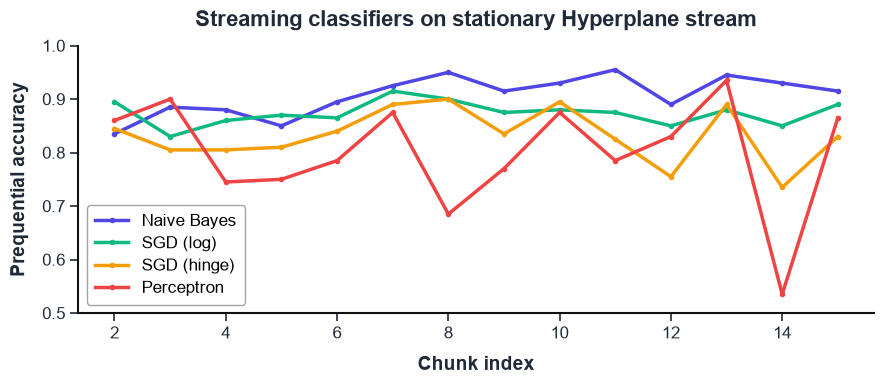

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
colors = ["#4f46e5", "#10b981", "#f59e0b", "#ef4444"]

for (name, accs), color in zip(comparison_results.items(), colors):
    ax.plot(range(2, n_hp_chunks + 1), accs, marker=".", label=name, color=color)

ax.set_xlabel("Chunk index")
ax.set_ylabel("Prequential accuracy")
ax.set_title("Streaming classifiers on stationary Hyperplane stream")
ax.set_ylim(0.5, 1.0)
ax.legend()
plt.tight_layout()
plt.show()


## 16.7 Streaming on a drifting Hyperplane stream

`Hyperplane` also supports continuous concept drift: setting `n_drift_features > 0` causes the decision boundary weights to rotate smoothly as new instances are generated. This tests an online learner's ability to track a moving target over time.


Hyperplane: 4000 samples, 10 features, 2 drifting features


Naive Bayes mean acc on drifting Hyperplane: 0.913


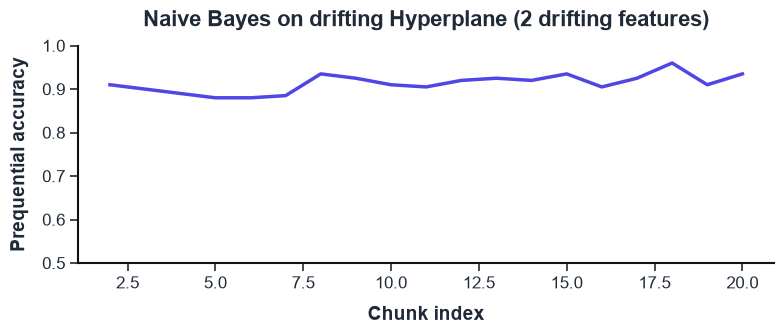

In [8]:
hp_drift = Hyperplane(
    n_samples=4000, n_features=10, n_drift_features=2, noise=0.05, random_state=42
).generate()
X_drift_hp, y_drift_hp = hp_drift.X, hp_drift.y
print(f"Hyperplane: {X_drift_hp.shape[0]} samples, {X_drift_hp.shape[1]} features, 2 drifting features")

n_drift_hp_chunks = X_drift_hp.shape[0] // CHUNK_SIZE
nb_hp = NaiveBayesClassifier()
hp_drift_accs = []

for i in range(n_drift_hp_chunks):
    start = i * CHUNK_SIZE
    end = start + CHUNK_SIZE
    Xi, yi = X_drift_hp[start:end], y_drift_hp[start:end]

    if i > 0:
        hp_drift_accs.append(accuracy_score(yi, nb_hp.predict(Xi)))
    nb_hp.partial_fit(Xi, yi)

print(f"Naive Bayes mean acc on drifting Hyperplane: {np.mean(hp_drift_accs):.3f}")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(range(2, n_drift_hp_chunks + 1), hp_drift_accs, color="#4f46e5")
ax.set_xlabel("Chunk index")
ax.set_ylabel("Prequential accuracy")
ax.set_title("Naive Bayes on drifting Hyperplane (2 drifting features)")
ax.set_ylim(0.5, 1.0)
plt.tight_layout()
plt.show()


## 16.8 Summary

Streaming in TuiML is built on `partial_fit`:

- **`NaiveBayesClassifier`** (`tuiml.algorithms.bayesian`) is a strong, scale-invariant default that maintains running probability estimates.
- **`SGDClassifier`** (`tuiml.algorithms.linear`) with `loss='hinge'` (linear SVM) or `loss='log'` (logistic regression) provides high-accuracy linear boundary updates when features are normalized.
- **`PerceptronClassifier`** (`tuiml.algorithms.neural`) provides lightweight linear decision boundary updates with single-pass weight adjustments.

**Prequential evaluation** (test-then-train) is the standard way to measure streaming performance honestly over time.

**Concept drift** requires adaptive strategies. While this tutorial demonstrated a simple accuracy-based drift heuristic that resets the model upon a sustained performance drop, production pipelines typically pair `partial_fit` with statistical drift detectors (such as ADWIN) or drift-aware adaptive learners.

> **Note.** For production streaming workloads with explicit drift detection algorithms (ADWIN, DDM, EDDM), install the optional CapyMOA extra: `pip install 'tuiml[capymoa]'`.
